# **Fitur Unik 2: Penjelasan Prediksi dengan Integrated Gradients**

Model final memberi satu angka probabilitas risiko diabetes. Untuk aplikasi kesehatan, angka saja tidak cukup. Pengguna perlu tahu **faktor apa yang membuat risikonya tinggi atau rendah**, dan tim pengembang perlu memastikan model mengambil keputusan berdasarkan pola yang masuk akal secara medis, bukan pola yang kebetulan.

Fitur unik kedua menjawab kebutuhan ini dengan **Integrated Gradients** (IG), metode atribusi untuk jaringan saraf dari Sundararajan dkk. (2017). IG menghitung kontribusi setiap fitur terhadap selisih probabilitas antara responden yang dijelaskan dan sebuah **baseline**. IG ditulis sendiri dengan `tf.GradientTape` di `src/inference.py`, jadi aplikasi memakai kode yang sama persis.

Supaya fitur ini tidak sekadar tampilan, dampaknya dibuktikan lewat empat pengujian di data validation:

| Pengujian | Pertanyaan yang dijawab |
|---|---|
| Completeness | Apakah jumlah kontribusi sama dengan selisih probabilitas |
| Deletion test | Apakah fitur yang ditunjuk IG benar-benar yang paling menggerakkan prediksi |
| Sensitivitas baseline | Apakah kesimpulan berubah kalau baseline diganti |
| Kesesuaian domain | Apakah arah pengaruh fitur sesuai dengan faktor risiko diabetes yang dikenal |

Model yang dijelaskan adalah model final (`models/mlp_final.keras`). Data test tetap tidak disentuh.

**Penanggung jawab:** Erik Hamli (231110980)

## **1. Import Library dan Konfigurasi**

Notebook ini tidak melatih model, jadi tidak ada saklar `RUN_EXPERIMENTS`. Seluruh perhitungan selesai dalam beberapa menit.

In [2]:
import sys
import json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from scipy.stats import spearmanr

from src import config
from src import preprocessing as prep
from src import evaluation as ev
from src import inference as inf
from src import visualization as viz

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
viz.set_style()
WARNA_NAIK, WARNA_TURUN, WARNA_UTAMA = "#eb6834", "#2a78d6", "#2a78d6"
rng = np.random.default_rng(config.SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## **2. Memuat Data dan Model Final**

Probabilitas model final di data validation dibandingkan dengan probabilitas yang tersimpan di notebook 05, untuk memastikan model yang dijelaskan adalah model yang sama.

In [3]:
data = prep.prepare_datasets()
assert data["test_fingerprint"] == prep.load_preprocessing_config()["split"]["test_fingerprint"]
model_cfg = json.loads((config.MODELS_DIR / "model_config.json").read_text(encoding="utf-8"))
model = keras.models.load_model(ROOT / model_cfg["model_path"], compile=False)
THRESHOLD = model_cfg["threshold"]

X_val, y_val = data["X_val"], data["y_val"].astype(int)
X_val_raw = data["X_val_raw"].reset_index(drop=True)
prob_val = inf.predict_proba(model, X_val)
prob_05 = np.load(config.RESULTS_DIR / "05_prob_validation_seed42.npz")["final"]

print(f"Model      : {model_cfg['model_path']} | loss {model_cfg['loss']} | threshold {THRESHOLD}")
print(f"Validation : {X_val.shape}")
print("Probabilitas sama dengan notebook 05:", np.allclose(prob_val, prob_05, atol=1e-6))

Model      : models/mlp_final.keras | loss BCE | threshold 0.13
Validation : (34332, 21)
Probabilitas sama dengan notebook 05: True


## **3. Menentukan Baseline**

IG selalu menjelaskan prediksi **relatif terhadap baseline**, jadi pemilihan baseline menentukan cara membaca hasilnya. Baseline yang dipakai adalah **rata-rata data train di ruang fitur yang sudah di-scaling**. Untuk fitur numerik dan ordinal, nilainya 0 (karena sudah distandardisasi). Untuk fitur biner, nilainya sama dengan proporsi "ya" di data train, misalnya 0,43 untuk `HighBP`.

Dengan baseline ini, kontribusi dibaca sebagai: **"dibanding responden rata-rata, fitur ini menaikkan atau menurunkan probabilitas diabetes sebesar sekian poin"**. Alternatif lain seperti vektor nol tidak punya makna yang jelas di data ini, karena nol untuk fitur biner berarti "tidak" pada semua pertanyaan, sedangkan nol untuk fitur ter-scaling berarti nilai rata-rata. Campuran keduanya bukan profil responden yang masuk akal (Sturmfels dkk., 2020).

In [4]:
baseline = data["X_train"].mean(axis=0).astype(np.float32)
baseline_prob = float(inf.predict_proba(model, baseline[None, :])[0])
baseline_raw = data["X_train_raw"].mean()

tabel_baseline = pd.DataFrame({
    "nama": [config.FEATURE_INFO[c]["nama"] for c in config.FEATURE_COLS],
    "rata-rata (nilai asli)": baseline_raw[config.FEATURE_COLS].values,
    "baseline (ter-scaling)": baseline,
}, index=config.FEATURE_COLS)
display(tabel_baseline.round(3))
print(f"Probabilitas diabetes untuk baseline : {baseline_prob:.4f}")
print(f"Proporsi diabetes di data train      : {data['y_train'].mean():.4f}")

,nama,rata-rata (nilai asli),baseline (ter-scaling)
HighBP,Tekanan darah tinggi,0.454,0.454
HighChol,Kolesterol tinggi,0.441,0.441
CholCheck,Cek kolesterol,0.959,0.959
BMI,Indeks massa tubuh,28.557,0.000
Smoker,Pernah merokok,0.465,0.465
Stroke,Riwayat stroke,0.045,0.045
HeartDiseaseorAttack,Penyakit jantung,0.104,0.104
PhysActivity,Aktivitas fisik,0.733,0.733
Fruits,Konsumsi buah,0.613,0.613
Veggies,Konsumsi sayur,0.794,0.794


Probabilitas diabetes untuk baseline : 0.1175
Proporsi diabetes di data train      : 0.1530


**Interpretasi:** Baseline berisi nilai rata-rata seluruh fitur di data train. Fitur numerik dan ordinal bernilai 0 setelah scaling, dengan nilai aslinya misalnya BMI 28,56, GenHlth 2,60, dan kelompok usia 8,09 (sekitar 55 sampai 59 tahun). Fitur biner bernilai sesuai proporsinya, misalnya `HighBP` 0,454 dan `CholCheck` 0,959.

Probabilitas diabetes untuk baseline adalah **0,1175**, lebih rendah dari proporsi diabetes di data train (0,1530). Selisih ini wajar karena model bersifat nonlinear. Probabilitas untuk "profil rata-rata" tidak sama dengan rata-rata probabilitas seluruh responden, yang di data validation sebesar 0,1397. Karena itu kontribusi IG dibaca sebagai **"dibanding profil responden rata-rata dengan risiko sekitar 11,7%"**, bukan dibanding risiko rata-rata populasi. Aplikasi juga harus menyebut pembanding ini dengan tepat.

## **4. Menentukan Jumlah Langkah Integral**

Integral pada IG dihitung secara numerik dengan aturan trapesium. Langkah yang terlalu sedikit membuat hasilnya tidak akurat. Akurasinya bisa diukur langsung lewat sifat **completeness**, yaitu jumlah kontribusi semua fitur seharusnya sama dengan probabilitas responden dikurangi probabilitas baseline.

Aturan pemilihan ditetapkan sebelum melihat hasil. Pilih jumlah langkah **terkecil** yang memenuhi dua syarat di seluruh data validation:
- kesalahan absolut maksimum kurang dari 0,01 (1 poin persen)
- median kesalahan relatif kurang dari 1%

In [5]:
selisih_target = prob_val - baseline_prob
hasil_langkah = []
for steps in [8, 16, 32, 64, 128]:
    attr = inf.integrated_gradients(model, X_val, baseline, steps=steps)
    err = np.abs(attr.sum(axis=1) - selisih_target)
    rel = err / np.maximum(np.abs(selisih_target), 1e-6)
    hasil_langkah.append({"langkah": steps, "rata-rata error": err.mean(), "error maksimum": err.max(),
                          "median error relatif": np.median(rel), "memenuhi syarat": bool(err.max() < 0.01 and np.median(rel) < 0.01)})
tabel_langkah = pd.DataFrame(hasil_langkah)
tabel_langkah.to_csv(config.RESULTS_DIR / "06_completeness_langkah.csv", index=False)
display(tabel_langkah.round(6))

STEPS = int(tabel_langkah.loc[tabel_langkah["memenuhi syarat"], "langkah"].min())
print("Jumlah langkah terpilih:", STEPS)

attr_val = inf.integrated_gradients(model, X_val, baseline, steps=STEPS)
err_final = np.abs(attr_val.sum(axis=1) - selisih_target)
print(f"Completeness pada {STEPS} langkah: rata-rata error {err_final.mean():.6f}, maksimum {err_final.max():.6f}")

,langkah,rata-rata error,error maksimum,median error relatif,memenuhi syarat
0,8,0.007168,0.080609,0.051612,False
1,16,0.003518,0.044446,0.027515,False
2,32,0.001711,0.022822,0.013238,False
3,64,0.000784,0.011838,0.006051,False
4,128,0.000383,0.006034,0.003015,True


Jumlah langkah terpilih: 128
Completeness pada 128 langkah: rata-rata error 0.000383, maksimum 0.006034


**Interpretasi:** Kesalahan completeness mengecil sekitar setengahnya setiap kali jumlah langkah digandakan, sesuai perilaku aturan trapesium. Dengan 8 sampai 64 langkah, error maksimumnya masih di atas 0,01 (pada 64 langkah error-nya 0,0118), jadi belum memenuhi syarat. **128 langkah** adalah jumlah terkecil yang lolos, dengan rata-rata error 0,000383 (0,04 poin persen) dan error maksimum 0,0060 di seluruh 34.332 responden. Model final dengan 4 layer dan BatchNorm punya permukaan output yang lebih melengkung, sehingga integralnya butuh langkah lebih banyak. Untuk satu responden di aplikasi, 128 langkah tetap selesai dalam sekejap.

Completeness yang terpenuhi ini penting, karena menjamin semua kontribusi yang ditampilkan di aplikasi jika dijumlahkan sama dengan selisih probabilitas responden terhadap baseline. Tidak ada bagian prediksi yang "hilang" dari penjelasan.

## **5. Kepentingan Fitur Secara Global**

Kepentingan global dihitung sebagai rata-rata nilai absolut kontribusi setiap fitur di seluruh 34.332 responden validation. Rata-rata kontribusi bertanda juga ditampilkan. Hasilnya dibandingkan dengan korelasi Spearman antara fitur dan label di data train, yang mirip dengan analisis di EDA, untuk melihat apakah model menangkap pola yang sama dengan data.

,nama,rata-rata |IG|,rata-rata IG,spearman dengan label (train),peringkat IG,peringkat |spearman|
GenHlth,Kesehatan umum,0.0539,0.0116,0.2727,1,1
BMI,Indeks massa tubuh,0.0444,-0.0030,0.2182,2,3
Age,Kelompok usia,0.0402,-0.0028,0.1753,3,6
HighBP,Tekanan darah tinggi,0.0341,0.0098,0.2559,4,2
HighChol,Kolesterol tinggi,0.0265,0.0031,0.1965,5,5
MentHlth,Hari kesehatan mental buruk,0.0145,0.0093,0.0185,6,21
Income,Pendapatan,0.0136,0.0001,-0.1388,7,8
HvyAlcoholConsump,Konsumsi alkohol berat,0.0090,0.0011,-0.0661,8,14
Sex,Jenis kelamin,0.0090,-0.0042,0.0316,9,17
HeartDiseaseorAttack,Penyakit jantung,0.0086,-0.0005,0.1671,10,7


Korelasi peringkat IG dengan peringkat |spearman| EDA: 0.573


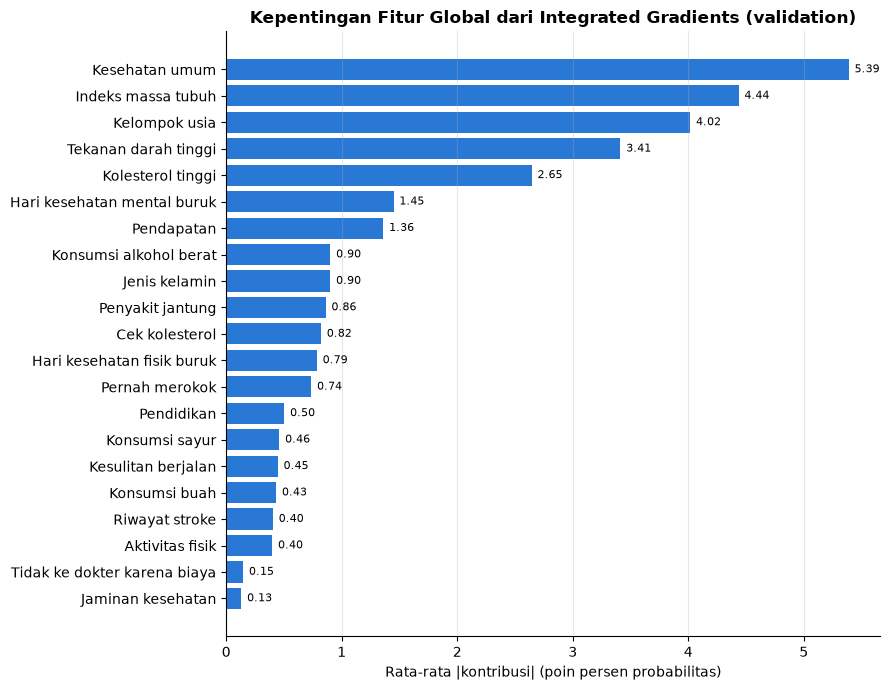

In [7]:
global_imp = pd.DataFrame({
    "nama": [config.FEATURE_INFO[c]["nama"] for c in config.FEATURE_COLS],
    "rata-rata |IG|": np.abs(attr_val).mean(axis=0),
    "rata-rata IG": attr_val.mean(axis=0),
}, index=config.FEATURE_COLS)
train_raw = data["X_train_raw"].assign(target=data["y_train"])
global_imp["spearman dengan label (train)"] = [spearmanr(train_raw[c], train_raw["target"])[0] for c in config.FEATURE_COLS]
global_imp["peringkat IG"] = global_imp["rata-rata |IG|"].rank(ascending=False).astype(int)
global_imp["peringkat |spearman|"] = global_imp["spearman dengan label (train)"].abs().rank(ascending=False).astype(int)
global_imp = global_imp.sort_values("rata-rata |IG|", ascending=False)
global_imp.to_csv(config.RESULTS_DIR / "06_importance_global.csv")
display(global_imp.round(4))

rho = spearmanr(global_imp["rata-rata |IG|"], global_imp["spearman dengan label (train)"].abs())[0]
print(f"Korelasi peringkat IG dengan peringkat |spearman| EDA: {rho:.3f}")

fig, ax = plt.subplots(figsize=(9, 7))
urut = global_imp.sort_values("rata-rata |IG|")
ax.barh(urut["nama"], urut["rata-rata |IG|"] * 100, color=WARNA_UTAMA)
for i, v in enumerate(urut["rata-rata |IG|"] * 100):
    ax.text(v + 0.05, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("Rata-rata |kontribusi| (poin persen probabilitas)")
ax.set_title("Kepentingan Fitur Global dari Integrated Gradients (validation)", fontweight="bold")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save_fig(fig, "fu2_01_importance_global")
plt.show()